In [1]:
from pathlib import Path
import numpy as np

In [2]:
results_dir = Path("hyperspot_project_files")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
segmentation_boundary = np.load(spotiphy_proj_dir / "segmentation" / "segmentation_boundary.npy", allow_pickle=True)
    # segmentation_boundary.shape

In [5]:
import numpy as np



segmentation_boundary = np.load(spotiphy_proj_dir / "segmentation" / "segmentation_boundary.npy", allow_pickle=True)
    # segmentation_boundary.shape

In [6]:
segmentation_boundary

array([[[5292.0615 , 6934.     ],
        [5292.3228 , 6936.451  ],
        [5292.4683 , 6939.1646 ],
        ...,
        [5289.48   , 6927.6655 ],
        [5290.552  , 6929.6294 ],
        [5291.2583 , 6931.7607 ]],

       [[4081.219  , 8176.     ],
        [4081.0054 , 8177.7915 ],
        [4080.5933 , 8179.5596 ],
        ...,
        [4079.5618 , 8170.9473 ],
        [4080.581  , 8172.446  ],
        [4080.9    , 8174.2295 ]],

       [[9311.094  ,  216.     ],
        [9310.331  ,  218.05495],
        [9309.4795 ,  219.92635],
        ...,
        [9309.157  ,  209.88159],
        [9310.584  ,  211.61578],
        [9310.938  ,  213.82413]],

       ...,

       [[5353.2466 , 2600.     ],
        [5352.468  , 2600.8887 ],
        [5351.6904 , 2601.5286 ],
        ...,
        [5353.128  , 2596.5737 ],
        [5353.593  , 2597.6833 ],
        [5353.4375 , 2598.9185 ]],

       [[4450.6265 , 3968.     ],
        [4451.5195 , 3969.8936 ],
        [4451.69   , 3972.0137 ],
        .

In [14]:
segmentation_boundary[:,:,0].max() * 0.05580357, segmentation_boundary[:,:,1].max() * 0.05580357

(np.float32(559.7948), np.float32(545.9842))

In [13]:
segmentation_boundary[:,:,0].max() * 0.18601191, segmentation_boundary[:,:,1].max() * 0.18601191

(np.float32(1865.9828), np.float32(1819.9474))

In [7]:
import squidpy as sq

adata = sq.datasets.mibitof()
adata.uns["spatial"].keys()

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

  0%|          | 0.00/19.3M [00:00<?, ?B/s]

dict_keys(['point16', 'point23', 'point8'])

In [10]:
adata.uns['spatial']

{'point16': {'images': {'hires': array([[[ 3,  3,  0],
           [ 2,  2,  0],
           [ 1,  1,  0],
           ...,
           [ 6, 15,  9],
           [ 2,  7,  5],
           [ 1,  3,  2]],
   
          [[ 5,  5,  0],
           [ 4,  4,  0],
           [ 2,  2,  0],
           ...,
           [ 6, 14,  7],
           [ 2,  6,  3],
           [ 1,  2,  1]],
   
          [[ 5,  5,  0],
           [ 4,  4,  0],
           [ 2,  2,  0],
           ...,
           [ 8, 15,  7],
           [ 3,  6,  2],
           [ 2,  3,  0]],
   
          ...,
   
          [[ 0,  0,  0],
           [ 0,  0,  0],
           [ 0,  0,  0],
           ...,
           [ 0,  0,  0],
           [ 0,  0,  0],
           [ 0,  0,  0]],
   
          [[ 0,  0,  0],
           [ 0,  0,  0],
           [ 0,  0,  0],
           ...,
           [ 0,  0,  0],
           [ 0,  0,  0],
           [ 0,  0,  0]],
   
          [[ 0,  0,  0],
           [ 0,  0,  0],
           [ 0,  0,  0],
           ...,
     

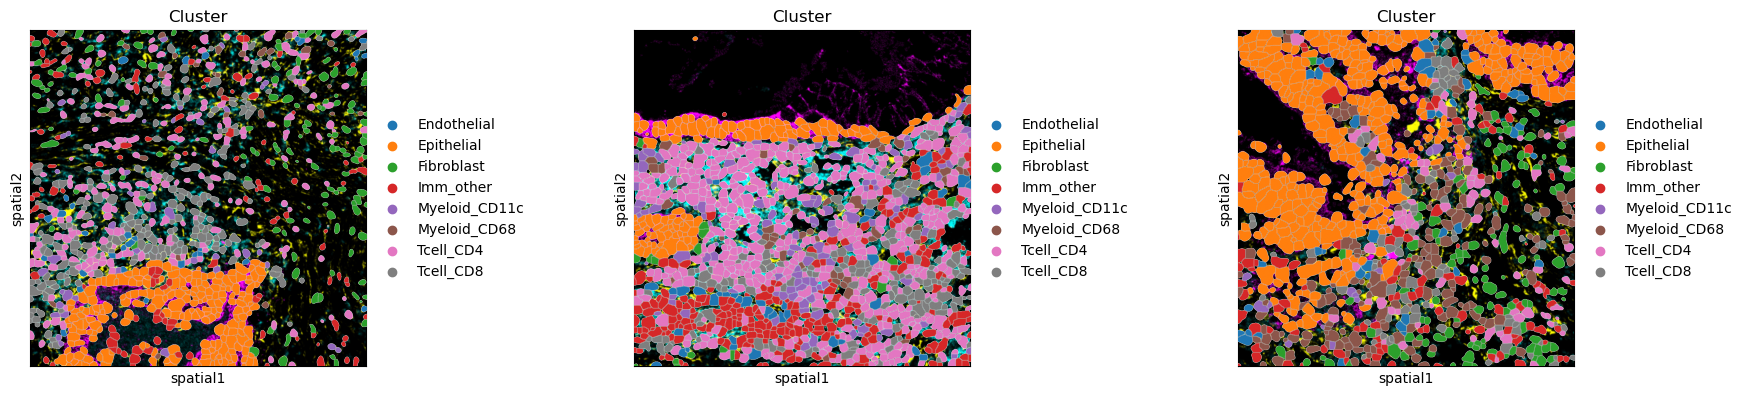

In [8]:
sq.pl.spatial_segment(
    adata, color="Cluster", library_key="library_id", seg_cell_id="cell_id"
)